=== SHAPES / DTYPES ===
X_train  shape=(900000, 1540) dtype=float64
X_test   shape=(100000, 1540) dtype=float64
y_train  shape=(900000,) dtype=float64
y_test   shape=(100000,) dtype=float64

Shot counts and feature length are consistent.

=== LABELS ===
train: values=[0. 1.], counts=[450000 450000], fractions=[0.5 0.5]
test: values=[0. 1.], counts=[50000 50000], fractions=[0.5 0.5]
y_train ndim: 1 (if 2D, labels may be one-hot or multi-qubit)

train subset: NaN=0, inf=0, min=-4224.000, max=4366.000, mean=57.585, std=843.953

test subset: NaN=0, inf=0, min=-4441.000, max=4558.000, mean=57.226, std=845.590

=== LAYOUT DETECTION (lower roughness = smoother = more likely correct) ===
concatenated I=[:770]      roughness = 110.54109
concatenated Q=[770:]      roughness = 48.04637
interleaved I=[0::2]       roughness = 9.10063
interleaved Q=[1::2]       roughness = 9.16709

--> Detected layout: interleaved  (CHECK THE PLOT TO CONFIRM)


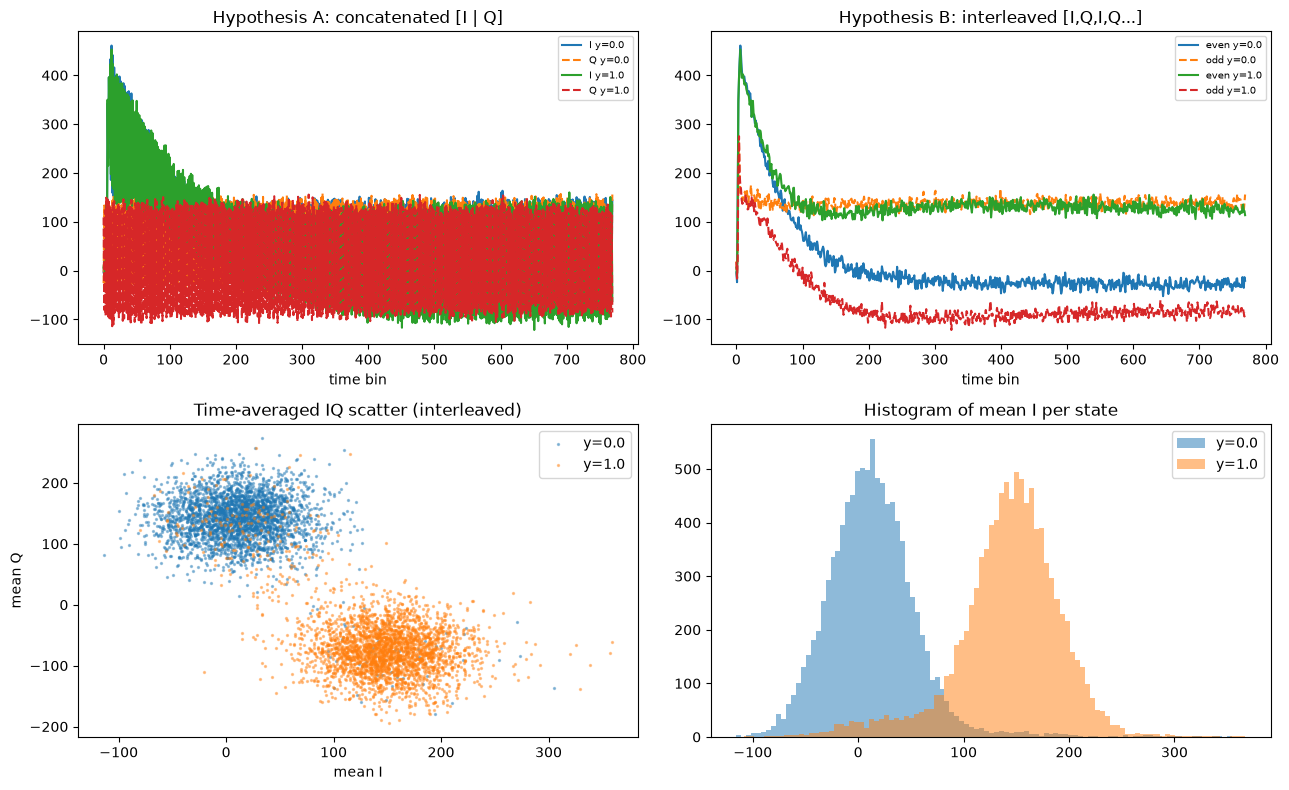


Boxcar + linear threshold on test subset: F0=0.9772, F1=0.9342, assignment fidelity=0.9557
(Sanity check only. If this is ~0.5, the layout or labels are wrong.)


In [1]:
"""
Step 0: load + sanity-check all 4 files of the QICK/hls4ml qubit readout dataset.
Never loads the full 11 GB train file into RAM (uses memory mapping).
"""
import os
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ paths
DATA_DIR = r"D:\MSU\Qubit_readout_FPGA"
FILES = {
    "X_train": "0528_X_train_0_770.npy",
    "X_test":  "0528_X_test_0_770.npy",
    "y_train": "0528_y_train_0_770.npy",
    "y_test":  "0528_y_test_0_770.npy",
}
N_SAMPLES = 770          # time bins per channel (1540 = 2 * 770)
SUBSET = 20_000          # shots used for plots / quick stats
SEED = 0


def path(key):
    return os.path.join(DATA_DIR, FILES[key])


# ------------------------------------------------------------------ load
X_train = np.load(path("X_train"), mmap_mode="r")
X_test = np.load(path("X_test"), mmap_mode="r")
y_train = np.load(path("y_train"))   # small, fine to load fully
y_test = np.load(path("y_test"))

print("=== SHAPES / DTYPES ===")
for name, arr in [("X_train", X_train), ("X_test", X_test),
                  ("y_train", y_train), ("y_test", y_test)]:
    print(f"{name:8s} shape={arr.shape} dtype={arr.dtype}")

# ------------------------------------------------------------------ consistency checks
assert X_train.shape[0] == y_train.shape[0], "X_train / y_train shot count mismatch"
assert X_test.shape[0] == y_test.shape[0], "X_test / y_test shot count mismatch"
assert X_train.shape[1] == X_test.shape[1], "train/test feature length mismatch"
assert X_train.shape[1] == 2 * N_SAMPLES, f"expected {2 * N_SAMPLES} features per shot"
print("\nShot counts and feature length are consistent.")

print("\n=== LABELS ===")
for name, y in [("train", y_train), ("test", y_test)]:
    vals, counts = np.unique(y, return_counts=True)
    print(f"{name}: values={vals}, counts={counts}, fractions={np.round(counts / counts.sum(), 4)}")
print("y_train ndim:", y_train.ndim, "(if 2D, labels may be one-hot or multi-qubit)")

# ------------------------------------------------------------------ random subsets
rng = np.random.default_rng(SEED)


def take_subset(X, y, n):
    idx = np.sort(rng.choice(X.shape[0], size=min(n, X.shape[0]), replace=False))
    return np.asarray(X[idx]), y[idx]


Xs_tr, ys_tr = take_subset(X_train, y_train, SUBSET)
Xs_te, ys_te = take_subset(X_test, y_test, SUBSET)

# ------------------------------------------------------------------ NaN / range check
for name, x in [("train subset", Xs_tr), ("test subset", Xs_te)]:
    print(f"\n{name}: NaN={np.isnan(x).sum()}, inf={np.isinf(x).sum()}, "
          f"min={x.min():.3f}, max={x.max():.3f}, mean={x.mean():.3f}, std={x.std():.3f}")

# ------------------------------------------------------------------ I/Q layout detection
# The correct layout gives a SMOOTH mean trace. Roughness = mean |second difference|.


def roughness(v):
    return np.mean(np.abs(np.diff(v, n=2)))


m = Xs_tr.mean(axis=0)
hyp = {
    "concatenated I=[:770]": m[:N_SAMPLES],
    "concatenated Q=[770:]": m[N_SAMPLES:],
    "interleaved I=[0::2]": m[0::2],
    "interleaved Q=[1::2]": m[1::2],
}
rough = {k: roughness(v) for k, v in hyp.items()}
print("\n=== LAYOUT DETECTION (lower roughness = smoother = more likely correct) ===")
for k, v in rough.items():
    print(f"{k:26s} roughness = {v:.5f}")

concat_score = rough["concatenated I=[:770]"] + rough["concatenated Q=[770:]"]
inter_score = rough["interleaved I=[0::2]"] + rough["interleaved Q=[1::2]"]
LAYOUT = "concatenated" if concat_score < inter_score else "interleaved"
print(f"\n--> Detected layout: {LAYOUT}  (CHECK THE PLOT TO CONFIRM)")


def split_iq(x, layout=LAYOUT):
    """Return I, Q arrays of shape (N, 770)."""
    if layout == "concatenated":
        return x[:, :N_SAMPLES], x[:, N_SAMPLES:]
    return x[:, 0::2], x[:, 1::2]


# ------------------------------------------------------------------ plots
labels = np.unique(ys_tr)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# mean traces under both hypotheses
for lab in labels:
    mm = Xs_tr[ys_tr == lab].mean(axis=0)
    axes[0, 0].plot(mm[:N_SAMPLES], label=f"I y={lab}")
    axes[0, 0].plot(mm[N_SAMPLES:], "--", label=f"Q y={lab}")
    axes[0, 1].plot(mm[0::2], label=f"even y={lab}")
    axes[0, 1].plot(mm[1::2], "--", label=f"odd y={lab}")
axes[0, 0].set_title("Hypothesis A: concatenated [I | Q]")
axes[0, 1].set_title("Hypothesis B: interleaved [I,Q,I,Q...]")
for a in axes[0]:
    a.set_xlabel("time bin")
    a.legend(fontsize=7)

# IQ scatter of time-averaged trace using detected layout
I, Q = split_iq(Xs_tr)
Imean, Qmean = I.mean(axis=1), Q.mean(axis=1)
for lab in labels:
    sel = ys_tr == lab
    axes[1, 0].scatter(Imean[sel][:3000], Qmean[sel][:3000], s=2, alpha=0.4, label=f"y={lab}")
axes[1, 0].set_title(f"Time-averaged IQ scatter ({LAYOUT})")
axes[1, 0].set_xlabel("mean I")
axes[1, 0].set_ylabel("mean Q")
axes[1, 0].legend()

# quick separation check: boxcar projection histogram
for lab in labels:
    sel = ys_tr == lab
    axes[1, 1].hist(Imean[sel], bins=100, alpha=0.5, label=f"y={lab}")
axes[1, 1].set_title("Histogram of mean I per state")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig("step0_inspection.png", dpi=130)
plt.show()

# ------------------------------------------------------------------ quick boxcar baseline (sanity only)
if len(labels) == 2:
    I_tr, Q_tr = split_iq(Xs_tr)
    I_te, Q_te = split_iq(Xs_te)
    f_tr = np.c_[I_tr.mean(1), Q_tr.mean(1)]
    f_te = np.c_[I_te.mean(1), Q_te.mean(1)]
    c0 = f_tr[ys_tr == labels[0]].mean(0)
    c1 = f_tr[ys_tr == labels[1]].mean(0)
    w = c1 - c0
    thr = 0.5 * (c0 + c1) @ w
    pred = (f_te @ w > thr).astype(int)
    truth = (ys_te == labels[1]).astype(int)
    f0 = np.mean(pred[truth == 0] == 0)
    f1 = np.mean(pred[truth == 1] == 1)
    print(f"\nBoxcar + linear threshold on test subset: "
          f"F0={f0:.4f}, F1={f1:.4f}, assignment fidelity={(f0 + f1) / 2:.4f}")
    print("(Sanity check only. If this is ~0.5, the layout or labels are wrong.)")


# ------------------------------------------------------------------ optional: float32 conversion (run once)
def convert_to_float32(src, dst, chunk=50_000):
    """Chunked float64 -> float32 conversion. ~5.5 GB for the train file."""
    X = np.load(src, mmap_mode="r")
    out = np.lib.format.open_memmap(dst, mode="w+", dtype=np.float32, shape=X.shape)
    for i in range(0, X.shape[0], chunk):
        out[i:i + chunk] = X[i:i + chunk].astype(np.float32)
    out.flush()
    print("wrote", dst)


# Uncomment to run once (needs ~6.2 GB free disk):
# convert_to_float32(path("X_test"),  os.path.join(DATA_DIR, "X_test_f32.npy"))
# convert_to_float32(path("X_train"), os.path.join(DATA_DIR, "X_train_f32.npy"))